In [1]:
import torch
import torch.nn.functional as F
import pandas as pd
import zlib
from tqdm import tqdm
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
from sklearn.metrics import roc_auc_score, roc_curve

dataset = load_dataset("UBC-SLIME/colx_531_group_project")
val_data = dataset["validation"]
test_data = dataset["test"]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
print("Using device:", device)

model_name = "UBC-SLIME/colx_531_smollm2-360m"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(model_name).to(device)
model.eval()

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token


def get_losses_batched(texts, max_length=512):
    enc = tokenizer(
        texts,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=max_length
    )
    input_ids = enc["input_ids"].to(device)
    attention_mask = enc["attention_mask"].to(device)

    with torch.no_grad():
        if use_amp:
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
        else:
            logits = model(input_ids=input_ids, attention_mask=attention_mask).logits

    shift_logits = logits[:, :-1, :]
    shift_labels = input_ids[:, 1:]
    shift_mask = attention_mask[:, 1:]

    token_losses = F.cross_entropy(
        shift_logits.reshape(-1, shift_logits.size(-1)),
        shift_labels.reshape(-1),
        reduction="none"
    ).reshape(shift_labels.size())

    token_losses = token_losses * shift_mask
    seq_losses = token_losses.sum(dim=1) / shift_mask.sum(dim=1).clamp(min=1)

    return seq_losses.cpu().numpy()


def compute_scores(texts, losses):
    return [
        -(loss / max(len(zlib.compress(text.encode("utf-8"))), 1))
        for text, loss in zip(texts, losses)
    ]


def run_split(split_data, split_name, batch_size=32):
    rows = []

    for start in tqdm(range(0, len(split_data), batch_size), desc=f"Scoring {split_name}"):
        batch = split_data[start:start + batch_size]
        texts = batch["text"]

        losses = get_losses_batched(texts)
        scores = compute_scores(texts, losses)

        for i, score in enumerate(scores):
            row = {
                "id": batch["id"][i],
                "score": score
            }
            if "is_member" in batch:
                row["is_member"] = batch["is_member"][i]
            rows.append(row)

    return pd.DataFrame(rows)


val_df = run_split(val_data, "validation", batch_size=32)
val_df.to_csv("validation_zlib_scores.csv", index=False)

y_true = val_df["is_member"].astype(int).values
y_score = val_df["score"].values

roc_auc = roc_auc_score(y_true, y_score)
fpr, tpr, _ = roc_curve(y_true, y_score)
tpr_at_fpr_01 = tpr[fpr <= 0.1][-1]

print("VALIDATION RESULTS")
print("Samples evaluated:", len(val_df))
print(f"ROC-AUC: {roc_auc:.6f}")
print(f"TPR@FPR=0.1: {tpr_at_fpr_01:.6f}")

test_df = run_split(test_data, "test", batch_size=32)
test_df[["id", "score"]].to_csv("submission_zlib.csv", index=False)

print("Saved files:")
print("validation_zlib_scores.csv")
print("submission_zlib.csv")

train.json:   0%|          | 0.00/102M [00:00<?, ?B/s]

dev.json:   0%|          | 0.00/20.2M [00:00<?, ?B/s]

test.json:   0%|          | 0.00/30.2M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/15000 [00:00<?, ? examples/s]

... (7 outputs left out)

Scoring validation: 100%|██████████| 313/313 [06:04<00:00,  1.17s/it]


VALIDATION RESULTS
Samples evaluated: 10000
ROC-AUC: 0.620802
TPR@FPR=0.1: 0.212000


Scoring test: 100%|██████████| 469/469 [10:14<00:00,  1.31s/it]

Saved files:
validation_zlib_scores.csv
submission_zlib.csv


In [12]:
# ----------------------------------------------------
# ERROR ANALYSIS
# ----------------------------------------------------

threshold = val_df["score"].median()

# Predicted label
val_df["pred"] = (val_df["score"] > threshold).astype(int)

# False positives and false negatives
false_pos = val_df[(val_df["pred"] == 1) & (val_df["is_member"] == 0)]
false_neg = val_df[(val_df["pred"] == 0) & (val_df["is_member"] == 1)]

print("\nERROR ANALYSIS")
print("False Positives:", len(false_pos))
print("False Negatives:", len(false_neg))

analysis_df = val_df.merge(val_text, on="id")
analysis_df["text_length"] = analysis_df["text"].apply(len)

false_pos_text = analysis_df[(analysis_df["pred"] == 1) & (analysis_df["is_member"] == 0)]
false_neg_text = analysis_df[(analysis_df["pred"] == 0) & (analysis_df["is_member"] == 1)]

print("\nAverage text length:")
print("False Positives:", false_pos_text["text_length"].mean())
print("False Negatives:", false_neg_text["text_length"].mean())


ERROR ANALYSIS
False Positives: 2089
False Negatives: 2090

Average text length:
False Positives: 2291.6237434179034
False Negatives: 1611.7631578947369


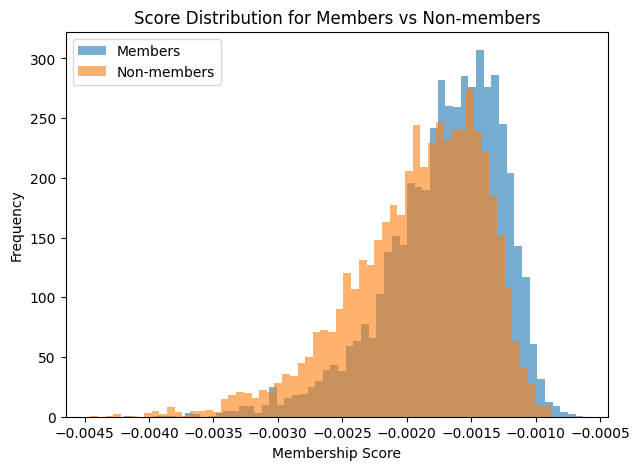

In [13]:
import matplotlib.pyplot as plt

members = val_df[val_df["is_member"] == 1]["score"]
non_members = val_df[val_df["is_member"] == 0]["score"]

plt.figure(figsize=(7,5))

plt.hist(members, bins=60, alpha=0.6, label="Members")
plt.hist(non_members, bins=60, alpha=0.6, label="Non-members")

plt.xlabel("Membership Score")
plt.ylabel("Frequency")
plt.title("Score Distribution for Members vs Non-members")
plt.legend()

plt.show()